# Benchmark Model Tabular Ordinal

1. baseline tanpa tuning (1 seed),
2. tuning Optuna,
3. retrain best hyperparameter (5 seed),
4. laporan mean ± std dan visualisasi enam metrik.

Model: TabM, RealMLP-TD-S, XGBoost, LightGBM, dan CatBoost.

## 1. Setup Kaggle

In [1]:
%pip install -q tabm optuna xgboost catboost lightgbm

import copy
import json
import random
import sys
import time
import urllib.request
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import optuna
import pandas as pd
import seaborn as sns
import torch
import torch.nn as nn
from catboost import CatBoostClassifier
from lightgbm import LGBMClassifier, early_stopping as lgb_early_stopping
from scipy.stats import spearmanr
from sklearn.metrics import (
    accuracy_score,
    cohen_kappa_score,
    mean_absolute_error,
    mean_squared_error,
    r2_score,
)
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from torch.utils.data import DataLoader, TensorDataset
from xgboost import XGBClassifier

sns.set_theme(style="whitegrid")

Note: you may need to restart the kernel to use updated packages.


## 2. Konfigurasi


In [2]:
BASELINE_SEED = 42
TUNING_SEED = 42
FINAL_SEEDS = [42, 123, 2024, 3407, 9999]

N_TRIALS = 100
RUN_BASELINE = True
RUN_TUNING = True
RUN_FINAL = True

TABM_BATCH_SIZE = 256
TABM_MAX_EPOCHS = 150
TABM_PATIENCE = 15
GPU_ID = 0

DATASET_FILES = {
    "melbourne_airbnb": "oc10_melbourneAirbnb.csv",
    "student_performance": "oc08_studentPerformance.csv",
    "nhanes": "oc05_nhanes.csv",
    "esl": "oc06_esl.csv",
    "lev": "oc05_lev.csv",
}
TUNABLE_MODELS = ["TabM", "XGBoost", "LightGBM", "CatBoost"]
ALL_MODELS = ["TabM", "RealMLP-TD-S", "XGBoost", "LightGBM", "CatBoost"]

WORK_DIR = Path("/kaggle/working") if Path("/kaggle/working").exists() else Path(".")
OUTPUT_DIR = WORK_DIR / "results"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

GPU_COUNT = torch.cuda.device_count()
if GPU_COUNT == 0:
    raise RuntimeError("GPU tidak ditemukan. Aktifkan accelerator GPU di Kaggle.")

DEVICE = torch.device(f"cuda:{GPU_ID}")
CATBOOST_DEVICES = ":".join(map(str, range(min(2, GPU_COUNT))))

print(f"DEVICE | PyTorch={DEVICE} | CatBoost={CATBOOST_DEVICES}")
for gpu_id in range(GPU_COUNT):
    print(f"GPU {gpu_id} | {torch.cuda.get_device_name(gpu_id)}")

DEVICE | PyTorch=cuda:0 | CatBoost=0:1
GPU 0 | Tesla T4
GPU 1 | Tesla T4


## 3. Load dataset dan RealMLP

In [3]:
def find_dataset(filename):
    roots = [Path("dataset"), Path("/kaggle/input"), Path("/kaggle/working")]
    for root in roots:
        if root.exists():
            matches = list(root.rglob(filename))
            if matches:
                return matches[0]
    raise FileNotFoundError(f"{filename} tidak ditemukan")


datasets = {
    name: pd.read_csv(find_dataset(filename))
    for name, filename in DATASET_FILES.items()
}

for name, df in datasets.items():
    if "y" not in df.columns:
        raise ValueError(f"{name}: kolom target 'y' tidak ditemukan")
    classes = sorted(df["y"].unique())
    if classes != list(range(len(classes))):
        raise ValueError(f"{name}: label harus berurutan dari 0, ditemukan {classes}")
    print(f"{name:22} shape={df.shape}, classes={len(classes)}")


def load_realmlp():
    folder = WORK_DIR / "_realmlp"
    folder.mkdir(exist_ok=True)
    for filename in ["preprocessing.py", "mlp.py"]:
        path = folder / filename
        if not path.exists():
            url = (
                "https://raw.githubusercontent.com/"
                "dholzmueller/realmlp-td-s_standalone/main/"
                f"{filename}"
            )
            urllib.request.urlretrieve(url, path)

    np.NaN = np.nan
    np.Inf = np.inf
    sys.path.insert(0, str(folder.resolve()))
    from mlp import Standalone_RealMLP_TD_S_Classifier
    return Standalone_RealMLP_TD_S_Classifier


RealMLPClassifier = load_realmlp()

melbourne_airbnb       shape=(20036, 49), classes=10
student_performance    shape=(662, 44), classes=8
nhanes                 shape=(5223, 31), classes=5
esl                    shape=(488, 5), classes=6
lev                    shape=(1000, 5), classes=5


## 4. Split dan metrik ordinal

Split train/validation/test adalah 70/15/15 dan stratified.

In [4]:
METRICS = ["r2", "spearman", "mae", "rmse", "qwk", "accuracy"]
HIGHER_IS_BETTER = {"r2", "spearman", "qwk", "accuracy"}


def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


def split_dataset(df, seed):
    X = df.drop(columns="y")
    y = df["y"].astype(int).to_numpy()

    X_train, X_temp, y_train, y_temp = train_test_split(
        X, y, test_size=0.30, stratify=y, random_state=seed
    )
    X_val, X_test, y_val, y_test = train_test_split(
        X_temp, y_temp, test_size=0.50, stratify=y_temp, random_state=seed
    )
    return X_train, X_val, X_test, y_train, y_val, y_test


def expected_class(probabilities):
    return probabilities @ np.arange(probabilities.shape[1])


def evaluate_ordinal(y_true, probabilities):
    score = expected_class(probabilities)
    prediction = np.clip(
        np.rint(score), 0, probabilities.shape[1] - 1
    ).astype(int)
    return {
        "r2": r2_score(y_true, score),
        "spearman": spearmanr(y_true, score).statistic,
        "mae": mean_absolute_error(y_true, score),
        "rmse": mean_squared_error(y_true, score) ** 0.5,
        "qwk": cohen_kappa_score(y_true, prediction, weights="quadratic"),
        "accuracy": accuracy_score(y_true, prediction),
    }


def summarize(results, include_std=True):
    columns = METRICS + ["training_seconds", "inference_seconds"]
    grouped = results.groupby(["dataset", "model"])[columns]
    if include_std:
        summary = grouped.agg(["mean", "std"])
    else:
        summary = grouped.mean()
        return summary.reset_index().round(4)
    summary.columns = [f"{metric}_{stat}" for metric, stat in summary.columns]
    return summary.reset_index().round(4)


def mean_std_table(results):
    mean = results.groupby(["dataset", "model"])[METRICS].mean()
    std = results.groupby(["dataset", "model"])[METRICS].std()
    table = mean.copy().astype(object)
    for metric in METRICS:
        table[metric] = [
            f"{m:.4f} ± {s:.4f}" if pd.notna(s) else f"{m:.4f}"
            for m, s in zip(mean[metric], std[metric])
        ]
    return table.reset_index()

## 5. Trainer TabM 


In [5]:
from tabm import TabM


BASELINE_TABM_PARAMS = {
    "n_blocks": 3,
    "d_block": 256,
    "lr": 2e-3,
    "weight_decay": 3e-4,
}


def make_loader(X, y, scaler, seed, shuffle):
    X_tensor = torch.tensor(scaler.transform(X), dtype=torch.float32)
    y_tensor = torch.tensor(y, dtype=torch.long)
    generator = torch.Generator().manual_seed(seed)
    return DataLoader(
        TensorDataset(X_tensor, y_tensor),
        batch_size=TABM_BATCH_SIZE,
        shuffle=shuffle,
        generator=generator,
        pin_memory=True,
    )


def predict_tabm(model, scaler, X):
    X_tensor = torch.tensor(scaler.transform(X), dtype=torch.float32)
    loader = DataLoader(X_tensor, batch_size=1024, shuffle=False)
    probabilities = []

    model.eval()
    with torch.inference_mode():
        for batch in loader:
            logits = model(batch.to(DEVICE, non_blocking=True))
            probabilities.append(torch.softmax(logits, dim=-1).mean(1).cpu())

    return torch.cat(probabilities).numpy()


def fit_tabm(X_train, y_train, X_val, y_val, n_classes, params, seed, trial=None):
    set_seed(seed)
    scaler = StandardScaler().fit(X_train)
    train_loader = make_loader(X_train, y_train, scaler, seed, shuffle=True)

    model = TabM.make(
        n_num_features=X_train.shape[1],
        cat_cardinalities=[],
        d_out=n_classes,
        n_blocks=params["n_blocks"],
        d_block=params["d_block"],
    ).to(DEVICE)
    optimizer = torch.optim.AdamW(
        model.parameters(),
        lr=params["lr"],
        weight_decay=params["weight_decay"],
    )

    best_state = None
    best_mae = np.inf
    patience = TABM_PATIENCE

    for epoch in range(TABM_MAX_EPOCHS):
        model.train()
        for X_batch, y_batch in train_loader:
            X_batch = X_batch.to(DEVICE, non_blocking=True)
            y_batch = y_batch.to(DEVICE, non_blocking=True)

            optimizer.zero_grad()
            logits = model(X_batch)
            loss = nn.functional.cross_entropy(
                logits.reshape(-1, n_classes),
                y_batch.repeat_interleave(model.k),
            )
            loss.backward()
            optimizer.step()

        val_probabilities = predict_tabm(model, scaler, X_val)
        val_mae = mean_absolute_error(y_val, expected_class(val_probabilities))
        if epoch == 0 or (epoch + 1) % 10 == 0:
            print(f"TabM | epoch={epoch + 1:03d} | val_MAE={val_mae:.4f}")

        if trial is not None:
            trial.report(val_mae, epoch)
            if trial.should_prune():
                raise optuna.TrialPruned()

        if val_mae < best_mae:
            best_mae = val_mae
            best_state = copy.deepcopy(model.state_dict())
            patience = TABM_PATIENCE
        else:
            patience -= 1
            if patience == 0:
                break

    model.load_state_dict(best_state)
    return model, scaler, best_mae, epoch + 1

## 6. Trainer model lainnya

In [6]:
def make_tree_model(model_name, params, n_classes, seed):
    if model_name == "XGBoost":
        return XGBClassifier(
            **params,
            objective="multi:softprob",
            num_class=n_classes,
            eval_metric="mlogloss",
            tree_method="hist",
            device=f"cuda:{GPU_ID}",
            early_stopping_rounds=50,
            random_state=seed,
            n_jobs=-1,
        )
    if model_name == "LightGBM":
        return LGBMClassifier(
            **params,
            objective="multiclass",
            num_class=n_classes,
            device_type="gpu",
            gpu_device_id=GPU_ID,
            gpu_use_dp=False,
            max_bin=63,
            random_state=seed,
            n_jobs=-1,
            verbosity=-1,
        )
    return CatBoostClassifier(
        **params,
        loss_function="MultiClass",
        eval_metric="MultiClass",
        task_type="GPU",
        devices=CATBOOST_DEVICES,
        random_seed=seed,
        verbose=False,
        allow_writing_files=False,
    )


def fit_tree_model(model_name, params, X_train, y_train, X_val, y_val, n_classes, seed):
    model = make_tree_model(model_name, params, n_classes, seed)
    if model_name == "LightGBM":
        model.fit(
            X_train,
            y_train,
            eval_set=[(X_val, y_val)],
            callbacks=[lgb_early_stopping(50, verbose=False)],
        )
    elif model_name == "CatBoost":
        model.fit(
            X_train,
            y_train,
            eval_set=(X_val, y_val),
            early_stopping_rounds=50,
            verbose=False,
        )
    else:
        model.fit(X_train, y_train, eval_set=[(X_val, y_val)], verbose=False)
    return model


def fit_predict(model_name, params, split, n_classes, seed):
    X_train, X_val, X_test, y_train, y_val, _ = split
    set_seed(seed)

    started = time.perf_counter()
    if model_name == "TabM":
        model, scaler, _, epochs = fit_tabm(
            X_train, y_train, X_val, y_val, n_classes, params, seed
        )
        device = str(DEVICE)
    elif model_name == "RealMLP-TD-S":
        model = RealMLPClassifier(device=str(DEVICE))
        model.fit(X_train, y_train, X_val, y_val)
        epochs = 256
        device = str(DEVICE)
    else:
        model = fit_tree_model(
            model_name, params, X_train, y_train, X_val, y_val, n_classes, seed
        )
        epochs = getattr(model, "best_iteration_", None)
        device = f"cuda:{CATBOOST_DEVICES}" if model_name == "CatBoost" else str(DEVICE)
    training_seconds = time.perf_counter() - started

    started = time.perf_counter()
    if model_name == "TabM":
        probabilities = predict_tabm(model, scaler, X_test)
    else:
        probabilities = model.predict_proba(X_test)
    inference_seconds = time.perf_counter() - started

    del model
    torch.cuda.empty_cache()
    return probabilities, training_seconds, inference_seconds, device, epochs

## 7. Baseline tanpa tuning — 1 seed

Baseline disimpan terpisah dan tidak diulang lima kali, sehingga dilaporkan sebagai nilai tunggal tanpa mean ± std.

In [7]:
def run_suite(name, seeds, params_lookup):
    output_path = OUTPUT_DIR / f"{name}_results_per_seed.csv"
    rows = []

    for dataset_name, df in datasets.items():
        n_classes = df["y"].nunique()
        for seed in seeds:
            split = split_dataset(df, seed)
            y_test = split[-1]

            for model_name in ALL_MODELS:
                params = params_lookup.get((dataset_name, model_name), {})
                probabilities, train_s, infer_s, device, epochs = fit_predict(
                    model_name, params, split, n_classes, seed
                )
                row = {
                    "experiment": name,
                    "dataset": dataset_name,
                    "model": model_name,
                    "seed": seed,
                    "device": device,
                    "epochs": epochs,
                    "training_seconds": train_s,
                    "inference_seconds": infer_s,
                    "params": json.dumps(params, sort_keys=True),
                }
                row.update(evaluate_ordinal(y_test, probabilities))
                rows.append(row)
                pd.DataFrame(rows).to_csv(output_path, index=False)
                print(
                    f"RUN | {name} | {dataset_name} | {model_name} | "
                    f"seed={seed} | MAE={row['mae']:.4f} | "
                    f"train={train_s:.2f}s | infer={infer_s:.2f}s | {device}"
                )

    return pd.DataFrame(rows)


baseline_params = {}
for dataset_name in datasets:
    baseline_params[(dataset_name, "TabM")] = BASELINE_TABM_PARAMS
    for model_name in ["XGBoost", "LightGBM", "CatBoost"]:
        baseline_params[(dataset_name, model_name)] = {}

if RUN_BASELINE:
    baseline_results = run_suite("baseline", [BASELINE_SEED], baseline_params)
    baseline_summary = summarize(baseline_results, include_std=False)
    baseline_summary.to_csv(OUTPUT_DIR / "baseline_summary.csv", index=False)
    print("SAVED | baseline CSV files")
    display(baseline_results)
    display(baseline_summary)

TabM | epoch=001 | val_MAE=1.3861
TabM | epoch=010 | val_MAE=1.1885
TabM | epoch=020 | val_MAE=1.1420
TabM | epoch=030 | val_MAE=1.1245
TabM | epoch=040 | val_MAE=1.1357
TabM | epoch=050 | val_MAE=1.1093
TabM | epoch=060 | val_MAE=1.1113
TabM | epoch=070 | val_MAE=1.1046
TabM | epoch=080 | val_MAE=1.1184
RUN | baseline | melbourne_airbnb | TabM | seed=42 | MAE=1.1168 | train=31.35s | infer=0.02s | cuda:0


/usr/local/lib/python3.12/dist-packages/sklearn/pipeline.py:62: FutureWarning: This Pipeline instance is not fitted yet. Call 'fit' with appropriate arguments before using other methods such as transform, predict, etc. This will raise an error in 1.8 instead of the current warning.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/pipeline.py:62: FutureWarning: This Pipeline instance is not fitted yet. Call 'fit' with appropriate arguments before using other methods such as transform, predict, etc. This will raise an error in 1.8 instead of the current warning.
  warnings.warn(


RUN | baseline | melbourne_airbnb | RealMLP-TD-S | seed=42 | MAE=1.2208 | train=67.41s | infer=0.01s | cuda:0


/usr/local/lib/python3.12/dist-packages/xgboost/core.py:751: UserWarning: [13:03:23] WARNING: /__w/xgboost/xgboost/src/common/error_msg.cc:62: Falling back to prediction using DMatrix due to mismatched devices. This might lead to higher memory usage and slower performance. XGBoost is running on: cuda:0, while the input data is on: cpu.
Potential solutions:
- Use a data structure that matches the device ordinal in the booster.
- Set the device for booster before call to inplace_predict.

This warning will only be shown once.

  return func(**kwargs)


RUN | baseline | melbourne_airbnb | XGBoost | seed=42 | MAE=1.1573 | train=1.86s | infer=0.02s | cuda:0


1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.
1 warning generated.


... (9 outputs left out)

/usr/local/lib/python3.12/dist-packages/sklearn/pipeline.py:62: FutureWarning: This Pipeline instance is not fitted yet. Call 'fit' with appropriate arguments before using other methods such as transform, predict, etc. This will raise an error in 1.8 instead of the current warning.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/pipeline.py:62: FutureWarning: This Pipeline instance is not fitted yet. Call 'fit' with appropriate arguments before using other methods such as transform, predict, etc. This will raise an error in 1.8 instead of the current warning.
  warnings.warn(


RUN | baseline | lev | RealMLP-TD-S | seed=42 | MAE=0.4944 | train=3.00s | infer=0.00s | cuda:0
RUN | baseline | lev | XGBoost | seed=42 | MAE=0.5145 | train=0.38s | infer=0.00s | cuda:0
RUN | baseline | lev | LightGBM | seed=42 | MAE=0.5082 | train=0.84s | infer=0.00s | cuda:0
RUN | baseline | lev | CatBoost | seed=42 | MAE=0.5100 | train=0.93s | infer=0.00s | cuda:0:1
SAVED | baseline CSV files


,experiment,dataset,model,seed,device,epochs,training_seconds,inference_seconds,params,r2,spearman,mae,rmse,qwk,accuracy
0,baseline,melbourne_airbnb,TabM,42,cuda:0,83.0,31.352312,0.024160,"{""d_block"": 256, ""lr"": 0.002, ""n_blocks"": 3, ""...",0.732247,0.852943,1.116795,1.554465,0.843110,0.339987
1,baseline,melbourne_airbnb,RealMLP-TD-S,42,cuda:0,256.0,67.413747,0.005409,{},0.706853,0.839753,1.220803,1.626507,0.816745,0.285096
2,baseline,melbourne_airbnb,XGBoost,42,cuda:0,NaN,1.855480,0.018983,{},0.728201,0.850392,1.157263,1.566165,0.832987,0.325349
3,baseline,melbourne_airbnb,LightGBM,42,cuda:0,69.0,7.326323,0.059008,{},0.730274,0.852378,1.148318,1.560180,0.835088,0.322023
4,baseline,melbourne_airbnb,CatBoost,42,cuda:0:1,312.0,5.040336,0.010755,{},0.735328,0.854160,1.136369,1.545494,0.842169,0.328343
5,baseline,student_performance,TabM,42,cuda:0,28.0,0.502132,0.003317,"{""d_block"": 256, ""lr"": 0.002, ""n_blocks"": 3, ""...",0.137674,0.466888,1.245761,1.644750,0.205206,0.250000
6,baseline,student_performance,RealMLP-TD-S,42,cuda:0,256.0,1.746393,0.002852,{},0.142989,0.441813,1.211591,1.639674,0.335737,0.320000
7,baseline,student_performance,XGBoost,42,cuda:0,NaN,0.514020,0.007431,{},0.165274,0.412548,1.265483,1.618215,0.259136,0.260000
8,baseline,student_performance,LightGBM,42,cuda:0,7.0,0.776272,0.001722,{},0.125512,0.381856,1.296267,1.656308,0.155982,0.260000
9,baseline,student_performance,CatBoost,42,cuda:0:1,49.0,1.144364,0.002406,{},0.138396,0.423598,1.280470,1.644061,0.173430,0.230000


,dataset,model,r2,spearman,mae,rmse,qwk,accuracy,training_seconds,inference_seconds
0,esl,CatBoost,0.8426,0.9242,0.3910,0.5157,0.8802,0.6351,1.6449,0.0009
1,esl,LightGBM,0.8320,0.9194,0.4072,0.5328,0.8828,0.6486,3.5564,0.0018
2,esl,RealMLP-TD-S,0.8380,0.9303,0.3856,0.5232,0.8780,0.6351,1.6053,0.0029
3,esl,TabM,0.8593,0.9324,0.3692,0.4876,0.9006,0.6892,0.7143,0.0031
4,esl,XGBoost,0.8273,0.9151,0.4004,0.5402,0.8703,0.6216,0.2666,0.0050
5,lev,CatBoost,0.5253,0.7424,0.5100,0.6554,0.6451,0.5733,0.9276,0.0008
6,lev,LightGBM,0.5339,0.7466,0.5082,0.6495,0.6364,0.5667,0.8359,0.0039
7,lev,RealMLP-TD-S,0.5573,0.7607,0.4944,0.6330,0.6921,0.5600,3.0044,0.0028
8,lev,TabM,0.5672,0.7546,0.4886,0.6259,0.7193,0.5867,1.1195,0.0025
9,lev,XGBoost,0.5061,0.7151,0.5145,0.6685,0.6345,0.5667,0.3822,0.0030


## 8. Search space Optuna

minimize validation MAE.

In [8]:
def suggest_params(trial, model_name):
    if model_name == "TabM":
        zero_decay = trial.suggest_categorical("weight_decay_zero", [True, False])
        return {
            "n_blocks": trial.suggest_int("n_blocks", 1, 5),
            "d_block": trial.suggest_int("d_block", 64, 1024, step=16),
            "lr": trial.suggest_float("lr", 1e-4, 5e-3, log=True),
            "weight_decay": (
                0.0
                if zero_decay
                else trial.suggest_float("weight_decay", 1e-4, 1e-1, log=True)
            ),
        }
    if model_name == "XGBoost":
        return {
            "n_estimators": trial.suggest_int("n_estimators", 200, 2000),
            "max_depth": trial.suggest_int("max_depth", 3, 10),
            "learning_rate": trial.suggest_float("learning_rate", 0.01, 0.3),
            "min_child_weight": trial.suggest_int("min_child_weight", 1, 10),
            "subsample": trial.suggest_float("subsample", 0.6, 1.0),
            "colsample_bytree": trial.suggest_float("colsample_bytree", 0.6, 1.0),
            "gamma": trial.suggest_float("gamma", 0.0, 5.0),
            "reg_alpha": trial.suggest_float("reg_alpha", 1e-8, 10.0, log=True),
            "reg_lambda": trial.suggest_float("reg_lambda", 1e-8, 10.0, log=True),
        }
    if model_name == "LightGBM":
        return {
            "n_estimators": trial.suggest_int("n_estimators", 200, 2000),
            "learning_rate": trial.suggest_float("learning_rate", 0.01, 0.3),
            "num_leaves": trial.suggest_int("num_leaves", 15, 255),
            "max_depth": trial.suggest_int("max_depth", 3, 12),
            "min_child_samples": trial.suggest_int("min_child_samples", 5, 100),
            "subsample": trial.suggest_float("subsample", 0.6, 1.0),
            "colsample_bytree": trial.suggest_float("colsample_bytree", 0.6, 1.0),
            "reg_alpha": trial.suggest_float("reg_alpha", 1e-8, 10.0, log=True),
            "reg_lambda": trial.suggest_float("reg_lambda", 1e-8, 10.0, log=True),
        }
    return {
        "iterations": trial.suggest_int("iterations", 200, 2000),
        "learning_rate": trial.suggest_float("learning_rate", 0.01, 0.3),
        "depth": trial.suggest_int("depth", 4, 10),
        "l2_leaf_reg": trial.suggest_float("l2_leaf_reg", 1.0, 20.0),
        "random_strength": trial.suggest_float("random_strength", 0.0, 10.0),
        "bagging_temperature": trial.suggest_float(
            "bagging_temperature", 0.0, 10.0
        ),
    }


def materialize_best_params(model_name, trial_params):
    params = dict(trial_params)
    if model_name == "TabM":
        zero_decay = params.pop("weight_decay_zero")
        if zero_decay:
            params["weight_decay"] = 0.0
    return params


def tuning_objective(trial, model_name, split, n_classes):
    X_train, X_val, _, y_train, y_val, _ = split
    params = suggest_params(trial, model_name)
    started = time.perf_counter()

    if model_name == "TabM":
        _, _, val_mae, _ = fit_tabm(
            X_train,
            y_train,
            X_val,
            y_val,
            n_classes,
            params,
            TUNING_SEED,
            trial,
        )
    else:
        model = fit_tree_model(
            model_name,
            params,
            X_train,
            y_train,
            X_val,
            y_val,
            n_classes,
            TUNING_SEED,
        )
        val_mae = mean_absolute_error(
            y_val, expected_class(model.predict_proba(X_val))
        )
        del model
        torch.cuda.empty_cache()

    trial.set_user_attr("training_seconds", time.perf_counter() - started)
    return val_mae

## 9. Jalankan tuning

In [9]:
def run_tuning():
    best = {}

    for dataset_name, df in datasets.items():
        split = split_dataset(df, TUNING_SEED)
        n_classes = df["y"].nunique()

        for model_name in TUNABLE_MODELS:
            study = optuna.create_study(
                direction="minimize",
                sampler=optuna.samplers.TPESampler(seed=TUNING_SEED),
                pruner=optuna.pruners.MedianPruner(n_startup_trials=5),
            )

            def show_trial(study, trial):
                if trial.value is not None:
                    print(
                        f"TUNE | {dataset_name} | {model_name} | "
                        f"trial={trial.number + 1}/{N_TRIALS} | "
                        f"val_MAE={trial.value:.4f}"
                    )

            study.optimize(
                lambda trial: tuning_objective(
                    trial, model_name, split, n_classes
                ),
                n_trials=N_TRIALS,
                callbacks=[show_trial],
            )

            params = materialize_best_params(
                model_name, study.best_params
            )
            best[(dataset_name, model_name)] = params
            study.trials_dataframe().to_csv(
                OUTPUT_DIR / f"optuna_{dataset_name}_{model_name}.csv",
                index=False,
            )
            print(
                f"{dataset_name:22} | {model_name:10} | "
                f"best validation MAE={study.best_value:.4f}"
            )

    serializable = {
        f"{dataset}::{model}": params
        for (dataset, model), params in best.items()
    }
    (OUTPUT_DIR / "best_hyperparameters.json").write_text(
        json.dumps(serializable, indent=2)
    )
    return best


def load_best_params():
    data = json.loads(
        (OUTPUT_DIR / "best_hyperparameters.json").read_text()
    )
    return {
        tuple(key.split("::", 1)): params
        for key, params in data.items()
    }


best_params = run_tuning() if RUN_TUNING else load_best_params()

[I 2026-08-19 13:04:20,005] A new study created in memory with name: no-name-44a7f03e-24fa-4b9e-b908-bda165376dea


TabM | epoch=001 | val_MAE=1.5022
TabM | epoch=010 | val_MAE=1.3105
TabM | epoch=020 | val_MAE=1.2439
TabM | epoch=030 | val_MAE=1.1907
TabM | epoch=040 | val_MAE=1.1807
TabM | epoch=050 | val_MAE=1.1384
TabM | epoch=060 | val_MAE=1.1305
TabM | epoch=070 | val_MAE=1.1238
TabM | epoch=080 | val_MAE=1.1323
TabM | epoch=090 | val_MAE=1.1167
TabM | epoch=100 | val_MAE=1.1124
TabM | epoch=110 | val_MAE=1.1101
TabM | epoch=120 | val_MAE=1.0980
TabM | epoch=130 | val_MAE=1.1065


[I 2026-08-19 13:07:45,801] Trial 0 finished with value: 1.09801450839823 and parameters: {'weight_decay_zero': False, 'n_blocks': 4, 'd_block': 640, 'lr': 0.00018410729205738696, 'weight_decay': 0.00029375384576328325}. Best is trial 0 with value: 1.09801450839823.


TUNE | melbourne_airbnb | TabM | trial=1/100 | val_MAE=1.0980
TabM | epoch=001 | val_MAE=2.0959
TabM | epoch=010 | val_MAE=1.3253
TabM | epoch=020 | val_MAE=1.2869
TabM | epoch=030 | val_MAE=1.2530
TabM | epoch=040 | val_MAE=1.2158
TabM | epoch=050 | val_MAE=1.1764
TabM | epoch=060 | val_MAE=1.1605
TabM | epoch=070 | val_MAE=1.1450
TabM | epoch=080 | val_MAE=1.1468
TabM | epoch=090 | val_MAE=1.1394
TabM | epoch=100 | val_MAE=1.1373
TabM | epoch=110 | val_MAE=1.1269
TabM | epoch=120 | val_MAE=1.1137
TabM | epoch=130 | val_MAE=1.1290
TabM | epoch=140 | val_MAE=1.1154


[I 2026-08-19 13:12:43,369] Trial 1 finished with value: 1.106626601330007 and parameters: {'weight_decay_zero': False, 'n_blocks': 4, 'd_block': 752, 'lr': 0.00010838581269344756, 'weight_decay': 0.0812324508558869}. Best is trial 0 with value: 1.09801450839823.


TabM | epoch=150 | val_MAE=1.1147
TUNE | melbourne_airbnb | TabM | trial=2/100 | val_MAE=1.1066
TabM | epoch=001 | val_MAE=2.3387
TabM | epoch=010 | val_MAE=1.3530
TabM | epoch=020 | val_MAE=1.3175
TabM | epoch=030 | val_MAE=1.3019
TabM | epoch=040 | val_MAE=1.2901
TabM | epoch=050 | val_MAE=1.2827
TabM | epoch=060 | val_MAE=1.2682
TabM | epoch=070 | val_MAE=1.2567
TabM | epoch=080 | val_MAE=1.2458
TabM | epoch=090 | val_MAE=1.2385
TabM | epoch=100 | val_MAE=1.2354
TabM | epoch=110 | val_MAE=1.2288
TabM | epoch=120 | val_MAE=1.2218
TabM | epoch=130 | val_MAE=1.2214
TabM | epoch=140 | val_MAE=1.2159


... (3,754 outputs left out)

[I 2026-08-19 15:42:25,488] Trial 98 finished with value: 0.45743389805356693 and parameters: {'iterations': 519, 'learning_rate': 0.19574010106106032, 'depth': 4, 'l2_leaf_reg': 17.579605282066602, 'random_strength': 2.019853675222227, 'bagging_temperature': 1.3274910483357556}. Best is trial 81 with value: 0.45426597616501313.


TUNE | lev | CatBoost | trial=99/100 | val_MAE=0.4574


[I 2026-08-19 15:42:26,559] Trial 99 finished with value: 0.4655534537800916 and parameters: {'iterations': 413, 'learning_rate': 0.23881818629180332, 'depth': 5, 'l2_leaf_reg': 16.580283865197355, 'random_strength': 1.734893445063722, 'bagging_temperature': 2.2347828608569666}. Best is trial 81 with value: 0.45426597616501313.


TUNE | lev | CatBoost | trial=100/100 | val_MAE=0.4656
lev                    | CatBoost   | best validation MAE=0.4543


## 10. Evaluasi final best hyperparameter — 5 seed

Empat model tuned memakai best parameter yang sama pada lima split seed. RealMLP tidak memiliki search space, sehingga tetap memakai konfigurasi resminya sebagai pembanding.

In [10]:
final_params = dict(best_params)
for dataset_name in datasets:
    final_params[(dataset_name, "RealMLP-TD-S")] = {}

if RUN_FINAL:
    tuned_results = run_suite("tuned", FINAL_SEEDS, final_params)
    tuned_summary = summarize(tuned_results)
    tuned_table = mean_std_table(tuned_results)

    tuned_summary.to_csv(OUTPUT_DIR / "tuned_summary.csv", index=False)
    tuned_table.to_csv(OUTPUT_DIR / "tuned_mean_std.csv", index=False)
    print("SAVED | tuned CSV files")

    display(tuned_results)
    display(tuned_table)

TabM | epoch=001 | val_MAE=1.3879
TabM | epoch=010 | val_MAE=1.1868
TabM | epoch=020 | val_MAE=1.1168
TabM | epoch=030 | val_MAE=1.0935
TabM | epoch=040 | val_MAE=1.1079
TabM | epoch=050 | val_MAE=1.0818
TabM | epoch=060 | val_MAE=1.0862
TabM | epoch=070 | val_MAE=1.0836
RUN | tuned | melbourne_airbnb | TabM | seed=42 | MAE=1.0950 | train=138.41s | infer=0.12s | cuda:0


/usr/local/lib/python3.12/dist-packages/sklearn/pipeline.py:62: FutureWarning: This Pipeline instance is not fitted yet. Call 'fit' with appropriate arguments before using other methods such as transform, predict, etc. This will raise an error in 1.8 instead of the current warning.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/pipeline.py:62: FutureWarning: This Pipeline instance is not fitted yet. Call 'fit' with appropriate arguments before using other methods such as transform, predict, etc. This will raise an error in 1.8 instead of the current warning.
  warnings.warn(


RUN | tuned | melbourne_airbnb | RealMLP-TD-S | seed=42 | MAE=1.2208 | train=80.56s | infer=0.01s | cuda:0
RUN | tuned | melbourne_airbnb | XGBoost | seed=42 | MAE=1.1195 | train=6.63s | infer=0.12s | cuda:0
RUN | tuned | melbourne_airbnb | LightGBM | seed=42 | MAE=1.1271 | train=42.71s | infer=0.73s | cuda:0
RUN | tuned | melbourne_airbnb | CatBoost | seed=42 | MAE=1.1249 | train=18.08s | infer=0.03s | cuda:0:1
TabM | epoch=001 | val_MAE=1.4872
TabM | epoch=010 | val_MAE=1.2592
TabM | epoch=020 | val_MAE=1.1604
TabM | epoch=030 | val_MAE=1.1476
TabM | epoch=040 | val_MAE=1.1330
TabM | epoch=050 | val_MAE=1.1301
TabM | epoch=060 | val_MAE=1.1258
RUN | tuned | melbourne_airbnb | TabM | seed=123 | MAE=1.0823 | train=125.30s | infer=0.12s | cuda:0


/usr/local/lib/python3.12/dist-packages/sklearn/pipeline.py:62: FutureWarning: This Pipeline instance is not fitted yet. Call 'fit' with appropriate arguments before using other methods such as transform, predict, etc. This will raise an error in 1.8 instead of the current warning.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/pipeline.py:62: FutureWarning: This Pipeline instance is not fitted yet. Call 'fit' with appropriate arguments before using other methods such as transform, predict, etc. This will raise an error in 1.8 instead of the current warning.
  warnings.warn(


RUN | tuned | melbourne_airbnb | RealMLP-TD-S | seed=123 | MAE=1.1842 | train=79.92s | infer=0.01s | cuda:0
RUN | tuned | melbourne_airbnb | XGBoost | seed=123 | MAE=1.1163 | train=5.51s | infer=0.09s | cuda:0
RUN | tuned | melbourne_airbnb | LightGBM | seed=123 | MAE=1.1113 | train=41.44s | infer=0.68s | cuda:0
RUN | tuned | melbourne_airbnb | CatBoost | seed=123 | MAE=1.1122 | train=14.99s | infer=0.02s | cuda:0:1
TabM | epoch=001 | val_MAE=1.3347
TabM | epoch=010 | val_MAE=1.1405
TabM | epoch=020 | val_MAE=1.0865
TabM | epoch=030 | val_MAE=1.0565
TabM | epoch=040 | val_MAE=1.0466
TabM | epoch=050 | val_MAE=1.0485
TabM | epoch=060 | val_MAE=1.0522
TabM | epoch=070 | val_MAE=1.0482
TabM | epoch=080 | val_MAE=1.0423
TabM | epoch=090 | val_MAE=1.0448
TabM | epoch=100 | val_MAE=1.0377
TabM | epoch=110 | val_MAE=1.0370
RUN | tuned | melbourne_airbnb | TabM | seed=2024 | MAE=1.1237 | train=221.10s | infer=0.12s | cuda:0


/usr/local/lib/python3.12/dist-packages/sklearn/pipeline.py:62: FutureWarning: This Pipeline instance is not fitted yet. Call 'fit' with appropriate arguments before using other methods such as transform, predict, etc. This will raise an error in 1.8 instead of the current warning.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/pipeline.py:62: FutureWarning: This Pipeline instance is not fitted yet. Call 'fit' with appropriate arguments before using other methods such as transform, predict, etc. This will raise an error in 1.8 instead of the current warning.
  warnings.warn(


... (43 outputs left out)

/usr/local/lib/python3.12/dist-packages/sklearn/pipeline.py:62: FutureWarning: This Pipeline instance is not fitted yet. Call 'fit' with appropriate arguments before using other methods such as transform, predict, etc. This will raise an error in 1.8 instead of the current warning.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/pipeline.py:62: FutureWarning: This Pipeline instance is not fitted yet. Call 'fit' with appropriate arguments before using other methods such as transform, predict, etc. This will raise an error in 1.8 instead of the current warning.
  warnings.warn(


RUN | tuned | lev | RealMLP-TD-S | seed=9999 | MAE=0.5386 | train=3.35s | infer=0.00s | cuda:0
RUN | tuned | lev | XGBoost | seed=9999 | MAE=0.5065 | train=0.67s | infer=0.02s | cuda:0
RUN | tuned | lev | LightGBM | seed=9999 | MAE=0.5219 | train=0.53s | infer=0.00s | cuda:0
RUN | tuned | lev | CatBoost | seed=9999 | MAE=0.5193 | train=1.26s | infer=0.00s | cuda:0:1
SAVED | tuned CSV files


,experiment,dataset,model,seed,device,epochs,training_seconds,inference_seconds,params,r2,spearman,mae,rmse,qwk,accuracy
0,tuned,melbourne_airbnb,TabM,42,cuda:0,73.0,138.411056,0.124598,"{""d_block"": 736, ""lr"": 0.0012111185358834042, ...",0.729350,0.853154,1.095029,1.562850,0.846896,0.363273
1,tuned,melbourne_airbnb,RealMLP-TD-S,42,cuda:0,256.0,80.563837,0.005993,{},0.706853,0.839753,1.220803,1.626507,0.816745,0.285096
2,tuned,melbourne_airbnb,XGBoost,42,cuda:0,NaN,6.629378,0.122910,"{""colsample_bytree"": 0.8207856520925864, ""gamm...",0.740246,0.857960,1.119469,1.531067,0.842932,0.335329
3,tuned,melbourne_airbnb,LightGBM,42,cuda:0,374.0,42.706891,0.734590,"{""colsample_bytree"": 0.679975911689332, ""learn...",0.737611,0.856249,1.127106,1.538814,0.841471,0.332668
4,tuned,melbourne_airbnb,CatBoost,42,cuda:0:1,822.0,18.083611,0.025452,"{""bagging_temperature"": 0.6486729446737025, ""d...",0.739159,0.855959,1.124899,1.534268,0.842375,0.329341
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
120,tuned,lev,TabM,9999,cuda:0,24.0,1.502378,0.005703,"{""d_block"": 976, ""lr"": 0.0038991275550822103, ...",0.524213,0.712243,0.509018,0.656167,0.671678,0.613333
121,tuned,lev,RealMLP-TD-S,9999,cuda:0,256.0,3.351110,0.002871,{},0.457738,0.669870,0.538573,0.700508,0.587444,0.560000
122,tuned,lev,XGBoost,9999,cuda:0,NaN,0.671229,0.020369,"{""colsample_bytree"": 0.7742490419508844, ""gamm...",0.516902,0.707534,0.506477,0.661189,0.690173,0.606667
123,tuned,lev,LightGBM,9999,cuda:0,69.0,0.534288,0.002654,"{""colsample_bytree"": 0.6322466670179434, ""lear...",0.502610,0.689847,0.521949,0.670899,0.637745,0.573333


,dataset,model,r2,spearman,mae,rmse,qwk,accuracy
0,esl,CatBoost,0.8464 ± 0.0360,0.9251 ± 0.0189,0.3690 ± 0.0372,0.5066 ± 0.0605,0.8929 ± 0.0272,0.6946 ± 0.0601
1,esl,LightGBM,0.8480 ± 0.0345,0.9231 ± 0.0197,0.3698 ± 0.0379,0.5041 ± 0.0585,0.8934 ± 0.0257,0.6919 ± 0.0500
2,esl,RealMLP-TD-S,0.8488 ± 0.0369,0.9312 ± 0.0129,0.3641 ± 0.0471,0.5023 ± 0.0628,0.8952 ± 0.0230,0.6946 ± 0.0638
3,esl,TabM,0.8530 ± 0.0335,0.9319 ± 0.0111,0.3522 ± 0.0390,0.4958 ± 0.0571,0.8987 ± 0.0238,0.6865 ± 0.0630
4,esl,XGBoost,0.8473 ± 0.0339,0.9239 ± 0.0177,0.3705 ± 0.0427,0.5054 ± 0.0571,0.8889 ± 0.0341,0.6838 ± 0.0847
5,lev,CatBoost,0.5230 ± 0.0377,0.7241 ± 0.0275,0.4995 ± 0.0164,0.6572 ± 0.0251,0.6412 ± 0.0331,0.5947 ± 0.0197
6,lev,LightGBM,0.5190 ± 0.0480,0.7205 ± 0.0362,0.5032 ± 0.0188,0.6597 ± 0.0321,0.6545 ± 0.0438,0.6013 ± 0.0238
7,lev,RealMLP-TD-S,0.5085 ± 0.0477,0.7201 ± 0.0370,0.5099 ± 0.0198,0.6669 ± 0.0316,0.6265 ± 0.0462,0.5707 ± 0.0138
8,lev,TabM,0.5287 ± 0.0412,0.7315 ± 0.0270,0.4889 ± 0.0189,0.6533 ± 0.0279,0.6908 ± 0.0171,0.6133 ± 0.0226
9,lev,XGBoost,0.5269 ± 0.0489,0.7258 ± 0.0331,0.4951 ± 0.0161,0.6543 ± 0.0329,0.6694 ± 0.0459,0.6027 ± 0.0101


## 11. Visualisasi metrik

Setiap metrik memakai heatmap terpisah agar skala tidak tercampur. Warna hijau lebih pekat berarti lebih baik; anotasi final menampilkan mean ± std.

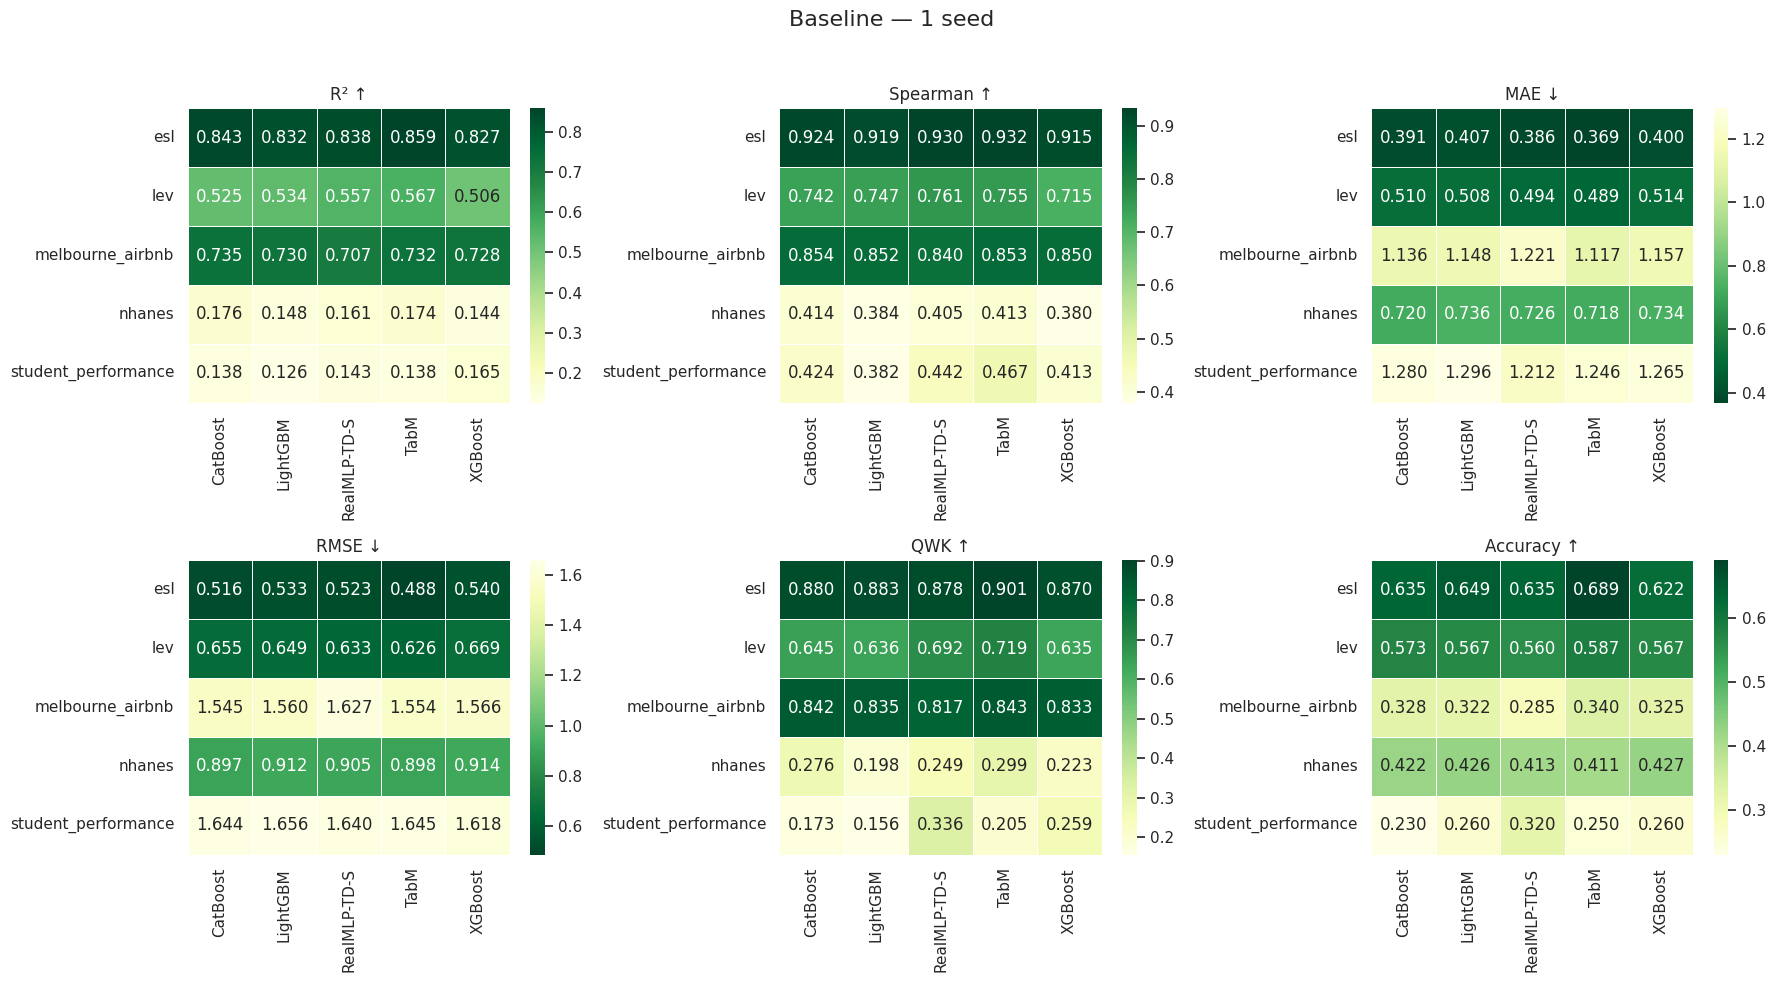

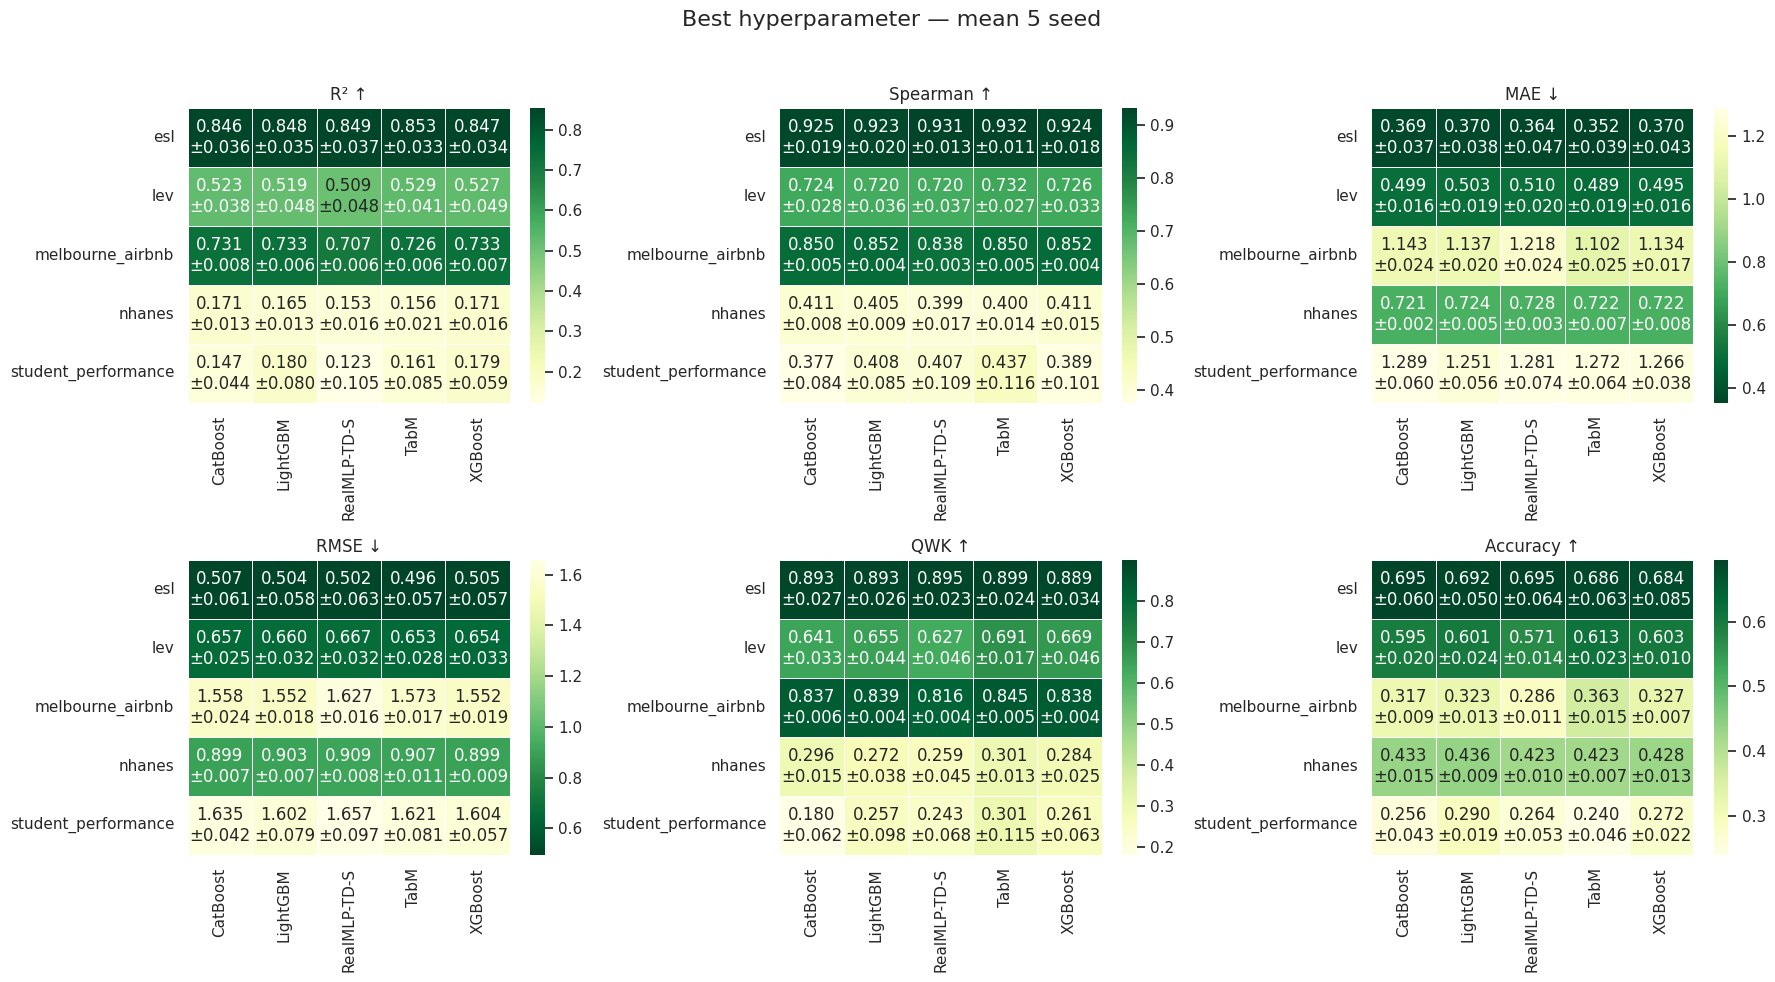

In [11]:
METRIC_LABELS = {
    "r2": "R² ↑",
    "spearman": "Spearman ↑",
    "mae": "MAE ↓",
    "rmse": "RMSE ↓",
    "qwk": "QWK ↑",
    "accuracy": "Accuracy ↑",
}


def plot_metrics(results, title, filename):
    grouped = results.groupby(["dataset", "model"])[METRICS]
    means = grouped.mean()
    stds = grouped.std()
    fig, axes = plt.subplots(2, 3, figsize=(18, 10))

    for metric, ax in zip(METRICS, axes.flat):
        matrix = means[metric].unstack("model")
        deviation = stds[metric].unstack("model")
        annotation = matrix.copy().astype(object)
        for row in matrix.index:
            for column in matrix.columns:
                mean = matrix.loc[row, column]
                std = deviation.loc[row, column]
                annotation.loc[row, column] = (
                    f"{mean:.3f}\n±{std:.3f}"
                    if pd.notna(std)
                    else f"{mean:.3f}"
                )
        cmap = "YlGn" if metric in HIGHER_IS_BETTER else "YlGn_r"
        sns.heatmap(
            matrix,
            annot=annotation,
            fmt="",
            cmap=cmap,
            linewidths=0.5,
            cbar=True,
            ax=ax,
        )
        ax.set_title(METRIC_LABELS[metric])
        ax.set_xlabel("")
        ax.set_ylabel("")

    fig.suptitle(title, fontsize=16)
    fig.tight_layout(rect=[0, 0, 1, 0.96])
    fig.savefig(OUTPUT_DIR / filename, dpi=160, bbox_inches="tight")
    plt.show()


if RUN_BASELINE:
    plot_metrics(baseline_results, "Baseline — 1 seed", "baseline_metrics.png")

if RUN_FINAL:
    plot_metrics(
        tuned_results,
        "Best hyperparameter — mean 5 seed",
        "tuned_metrics.png",
    )